In [19]:
import ThreeD_MoMs
import MoM
import numpy as np

- [`dodaj`](#dodaj)
- [`pobierz_dane`](#pobierz_dane)

In [20]:
import pickle
with open("faces_simple.pkl", "rb") as file:
    faces = pickle.load(file)
with open("vert_simple.pkl", "rb") as file:
    vertices = pickle.load(file)
epsilon = 8.8541878e-12;#// [F/m]
mu = 1.2566371e-6; #[H/m]

fn, fn_pm = ThreeD_MoMs.create_edge_tables( vertices, faces, 0)
Z_EJ, Z_nHJ = ThreeD_MoMs.L_mn(vertices, faces, fn, fn_pm, 100e6)

Z_EJ = Z_EJ[1:,1:]
Z_nHJ = Z_nHJ[1:,1:]
alpha = 0.5

Z_CFIE = (1-alpha)*Z_EJ+alpha*np.sqrt(mu/epsilon)*Z_nHJ

Z_CFIE_inv = np.linalg.inv(Z_CFIE)


Start!
blocks =  8
threads =  128
N =  30
buf_verticies.size =  39
buf_faces.size =  147
buf_face_curr.size =  183
buf_edges.size =  124
_face_curr[2] =  0


In [14]:
create_mesh_fun = MoM.mesh_creator2D(-3.4, 3.4, -3.4, 3.4, -0.0)
r = create_mesh_fun()

In [15]:
Es_r, Hs_r = MoM.MoM_exc(vertices, faces, fn, fn_pm, MoM.V_m_by_theta_creator(180, "xz"), 100e6, create_mesh_fun, Z_CFIE_inv)

start!


In [16]:
E_i = MoM.E_i_by_theta(180, "xz", r, 100e6)
E_sum = np.linalg.norm(Es_r+E_i, axis = 1)

In [17]:
import matplotlib.tri as mtri
import matplotlib.pyplot as plt


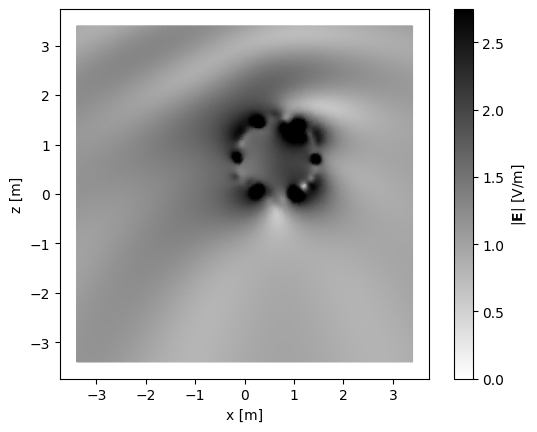

In [18]:
tri = mtri.Triangulation(r[:, 0], r[:, 2])
vmin, vmax = np.percentile(E_sum, [2, 99])
        
tpc = plt.tripcolor(tri, E_sum, cmap="gray_r", vmin=0, vmax=vmax, shading="gouraud")
plt.colorbar(tpc, label=r"|$\mathbf{E}$| [V/m]")
plt.gca().set_aspect("equal")
plt.xlabel("x [m]")
plt.ylabel("z [m]")
plt.show()